In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import shapiro
import scipy.stats as stats

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [3]:
# Load your cleaned dataset
df = pd.read_csv("CONDO_CLEAN.csv")
df.head()

,LOCATION,PRICE,ROOMS,BATHROOMS,CAR_PARKS,PROPERTY_BASE,PROPERTY_TYPE,BUILT-UP,FURNISHING _STATUS
0,BRICKFIELDS,10.0,NaN,NaN,NaN,CONDOMINIUM,OTHER,NaN,NaN
1,CHERAS,408.0,3,2.0,NaN,CONDOMINIUM,OTHER,NaN,NaN
2,KLCC,493.0,1,1.0,NaN,SERVICED RESIDENCE,OTHER,NaN,FULLY FURNISHED
3,CHERAS,530.0,3,2.0,1.0,CONDOMINIUM,INTERMEDIATE,22x70,FULLY FURNISHED
4,SETAPAK,650.0,3,2.0,2.0,SERVICED RESIDENCE,INTERMEDIATE,1270,PARTLY FURNISHED


In [4]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36783 entries, 0 to 36782
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   LOCATION            36783 non-null  object 
 1   PRICE               36631 non-null  float64
 2   ROOMS               36404 non-null  object 
 3   BATHROOMS           36178 non-null  float64
 4   CAR_PARKS           28313 non-null  float64
 5   PROPERTY_BASE       36783 non-null  object 
 6   PROPERTY_TYPE       36782 non-null  object 
 7   BUILT-UP            36024 non-null  object 
 8   FURNISHING _STATUS  32756 non-null  object 
dtypes: float64(3), object(6)
memory usage: 2.5+ MB
None


In [5]:
df.describe()

,PRICE,BATHROOMS,CAR_PARKS
count,3.663100e+04,36178.000000,28313.000000
mean,1.452985e+06,2.641163,1.739943
std,1.461108e+07,1.264609,0.816573
min,1.000000e+01,1.000000,1.000000
25%,5.500000e+05,2.000000,1.000000
50%,8.500000e+05,2.000000,2.000000
75%,1.500000e+06,3.000000,2.000000
max,1.980000e+09,20.000000,13.000000


In [6]:
df['ROOMS'] = pd.to_numeric(df['ROOMS'], errors='coerce')

In [7]:
df['BUILT-UP'] = pd.to_numeric(df['BUILT-UP'], errors='coerce')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36783 entries, 0 to 36782
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   LOCATION            36783 non-null  object 
 1   PRICE               36631 non-null  float64
 2   ROOMS               36386 non-null  float64
 3   BATHROOMS           36178 non-null  float64
 4   CAR_PARKS           28313 non-null  float64
 5   PROPERTY_BASE       36783 non-null  object 
 6   PROPERTY_TYPE       36782 non-null  object 
 7   BUILT-UP            35928 non-null  float64
 8   FURNISHING _STATUS  32756 non-null  object 
dtypes: float64(5), object(4)
memory usage: 2.5+ MB


In [9]:
missing_counts = df.isnull().sum()
print(missing_counts)

LOCATION                 0
PRICE                  152
ROOMS                  397
BATHROOMS              605
CAR_PARKS             8470
PROPERTY_BASE            0
PROPERTY_TYPE            1
BUILT-UP               855
FURNISHING _STATUS    4027
dtype: int64


In [10]:
df_cleaned = df.dropna()

In [11]:
has_missing = df.isnull().values.any()
print(has_missing)

True


In [12]:
df_cleaned['ROOMS'].isnull().sum()

np.int64(0)

In [13]:
print(df_cleaned.info())

<class 'pandas.core.frame.DataFrame'>
Index: 24638 entries, 4 to 36624
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   LOCATION            24638 non-null  object 
 1   PRICE               24638 non-null  float64
 2   ROOMS               24638 non-null  float64
 3   BATHROOMS           24638 non-null  float64
 4   CAR_PARKS           24638 non-null  float64
 5   PROPERTY_BASE       24638 non-null  object 
 6   PROPERTY_TYPE       24638 non-null  object 
 7   BUILT-UP            24638 non-null  float64
 8   FURNISHING _STATUS  24638 non-null  object 
dtypes: float64(5), object(4)
memory usage: 1.9+ MB
None


In [14]:
# Check dupliation
duplicate_count = df_cleaned.duplicated().sum()
print(f"Total duplicate rows: {duplicate_count}")

Total duplicate rows: 2789


In [15]:
# keep='first' (default) marks all duplicates as True except for the first occurrence
duplicate_rows = df_cleaned[df_cleaned.duplicated()]
print(duplicate_rows)

                  LOCATION       PRICE  ROOMS  BATHROOMS  CAR_PARKS  \
135                 PANTAI      2300.0    1.0        2.0        1.0   
183    TAMAN TUN DR ISMAIL      2800.0    3.0        2.0        1.0   
219                   KLCC      3300.0    1.0        2.0        1.0   
220                   KLCC      3300.0    1.0        2.0        1.0   
252                BANGSAR      3900.0    2.0        2.0        2.0   
...                    ...         ...    ...        ...        ...   
36430        BUKIT BINTANG   8800000.0    5.0        5.0        2.0   
36464              BANGSAR   9246600.0    5.0        6.0        3.0   
36492                 KLCC   9600000.0    4.0        4.0        2.0   
36502                 KLCC   9800000.0    7.0        6.0        3.0   
36588                 KLCC  12660000.0    4.0        4.0        2.0   

             PROPERTY_BASE PROPERTY_TYPE  BUILT-UP FURNISHING _STATUS  
135    SERVICED RESIDENCE         DUPLEX     750.0   PARTLY FURNISHED  
183

In [16]:
# remove and update duplicates
df_cleaned.drop_duplicates(inplace=True)

C:\Users\User\AppData\Local\Temp\ipykernel_29208\2606565119.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cleaned.drop_duplicates(inplace=True)


In [17]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21849 entries, 4 to 36624
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   LOCATION            21849 non-null  object 
 1   PRICE               21849 non-null  float64
 2   ROOMS               21849 non-null  float64
 3   BATHROOMS           21849 non-null  float64
 4   CAR_PARKS           21849 non-null  float64
 5   PROPERTY_BASE       21849 non-null  object 
 6   PROPERTY_TYPE       21849 non-null  object 
 7   BUILT-UP            21849 non-null  float64
 8   FURNISHING _STATUS  21849 non-null  object 
dtypes: float64(5), object(4)
memory usage: 1.7+ MB


In [18]:
print(df_cleaned.info())


<class 'pandas.core.frame.DataFrame'>
Index: 21849 entries, 4 to 36624
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   LOCATION            21849 non-null  object 
 1   PRICE               21849 non-null  float64
 2   ROOMS               21849 non-null  float64
 3   BATHROOMS           21849 non-null  float64
 4   CAR_PARKS           21849 non-null  float64
 5   PROPERTY_BASE       21849 non-null  object 
 6   PROPERTY_TYPE       21849 non-null  object 
 7   BUILT-UP            21849 non-null  float64
 8   FURNISHING _STATUS  21849 non-null  object 
dtypes: float64(5), object(4)
memory usage: 1.7+ MB
None


In [19]:
df_cleaned.describe()

,PRICE,ROOMS,BATHROOMS,CAR_PARKS,BUILT-UP
count,2.184900e+04,21849.000000,21849.000000,21849.000000,21849.000000
mean,1.291826e+06,3.229667,2.646117,1.742505,1712.811145
std,1.358407e+06,1.137224,1.230668,0.824085,8980.611525
min,6.500000e+02,1.000000,1.000000,1.000000,0.000000
25%,5.600000e+05,3.000000,2.000000,1.000000,980.000000
50%,8.400000e+05,3.000000,2.000000,2.000000,1250.000000
75%,1.500000e+06,4.000000,3.000000,2.000000,1711.000000
max,4.054234e+07,11.000000,20.000000,13.000000,790000.000000


In [20]:
# 1. Handle non-numeric text, placeholders, and missing values in BUILT-UP
# Using errors='coerce' forces text like 'nil' or 'unknown' into NaN, which are then dropped.

df_cleaned.dropna(subset=['BUILT-UP'], inplace=True)

# 2. Filter out likely rental prices and severe low-end price typos
# Keeps only properties where PRICE is RM100,000 or greater
df_cleaned = df_cleaned[df_cleaned['PRICE'] >= 100000]

# 3. Remove lower-bound structural errors in BUILT-UP
# Drops values under 100 (fixes decimal typos and sqm vs sqft mix-ups)
df_cleaned = df_cleaned[df_cleaned['BUILT-UP'] >= 100]

# 4. Remove extreme upper-bound outliers and systemic duplication errors
# Establishes a strict ceiling of 15,000 sqft
df_cleaned = df_cleaned[df_cleaned['BUILT-UP'] <= 15000]

# Optional: Reset the index after dropping rows to keep the dataframe clean
df_cleaned.reset_index(drop=True, inplace=True)

# Print a quick validation to confirm the current boundaries of the dataset
print(f"Total records remaining: {len(df_cleaned)}")
print(f"PRICE range: RM {df_cleaned['PRICE'].min():,.0f} to RM {df_cleaned['PRICE'].max():,.0f}")
print(f"BUILT-UP range: {df_cleaned['BUILT-UP'].min():,.0f} sqft to {df_cleaned['BUILT-UP'].max():,.0f} sqft")

Total records remaining: 21558
PRICE range: RM 200,000 to RM 40,542,340
BUILT-UP range: 189 sqft to 14,570 sqft


C:\Users\User\AppData\Local\Temp\ipykernel_29208\3580443986.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cleaned.dropna(subset=['BUILT-UP'], inplace=True)


In [21]:
df_cleaned.describe()

,PRICE,ROOMS,BATHROOMS,CAR_PARKS,BUILT-UP
count,2.155800e+04,21558.000000,21558.000000,21558.000000,21558.000000
mean,1.302288e+06,3.230031,2.646628,1.743390,1551.823407
std,1.345837e+06,1.136797,1.231553,0.822923,988.406586
min,2.000000e+05,1.000000,1.000000,1.000000,189.000000
25%,5.650000e+05,3.000000,2.000000,1.000000,985.000000
50%,8.500000e+05,3.000000,2.000000,2.000000,1250.000000
75%,1.500000e+06,4.000000,3.000000,2.000000,1712.000000
max,4.054234e+07,10.000000,20.000000,13.000000,14570.000000


In [22]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21558 entries, 0 to 21557
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   LOCATION            21558 non-null  object 
 1   PRICE               21558 non-null  float64
 2   ROOMS               21558 non-null  float64
 3   BATHROOMS           21558 non-null  float64
 4   CAR_PARKS           21558 non-null  float64
 5   PROPERTY_BASE       21558 non-null  object 
 6   PROPERTY_TYPE       21558 non-null  object 
 7   BUILT-UP            21558 non-null  float64
 8   FURNISHING _STATUS  21558 non-null  object 
dtypes: float64(5), object(4)
memory usage: 1.5+ MB


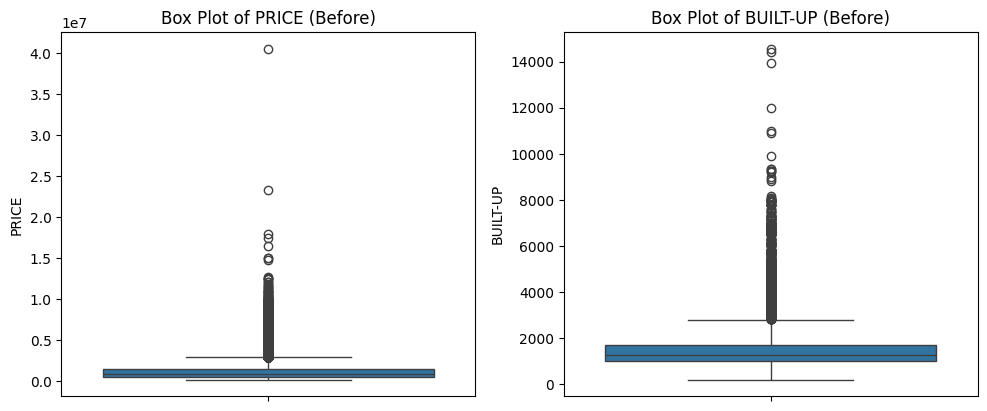

--- Outlier Summary ---
PRICE: 1724 outliers found.
BUILT-UP: 1422 outliers found.

Size before outlier removal: 21558 rows
Size after outlier removal: 18412 rows


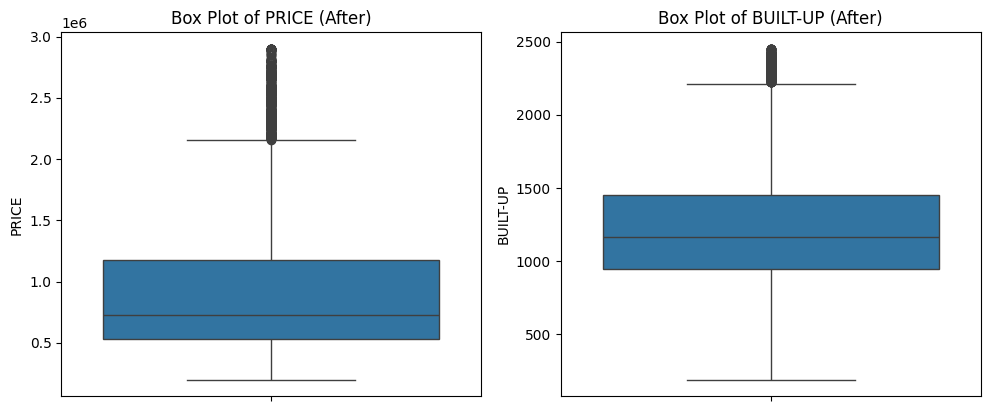

In [23]:
# Check for outliers and remove outliers

# 1. Define your continuous variables
numeric_cols = ['PRICE','BUILT-UP']

# 2. Plot Box Plots BEFORE cleaning (using your existing df_cleaned)
plt.figure(figsize=(15, 8)) 
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df_cleaned[col])
    plt.title(f'Box Plot of {col} (Before)')
plt.tight_layout()
plt.show()

# 3. Check and Remove Outliers using IQR
# Create your new variable here by copying the starting data
df_cleaned_iqr = df_cleaned.copy()
size_before_outliers = len(df_cleaned_iqr)

print("--- Outlier Summary ---")
for col in numeric_cols:
    Q1 = df_cleaned_iqr[col].quantile(0.25)
    Q3 = df_cleaned_iqr[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Count outliers
    outliers_mask = (df_cleaned_iqr[col] < lower_bound) | (df_cleaned_iqr[col] > upper_bound)
    print(f"{col}: {outliers_mask.sum()} outliers found.")
    
    # Remove outliers and save the result to the new variable
    df_cleaned_iqr = df_cleaned_iqr[(df_cleaned_iqr[col] >= lower_bound) & (df_cleaned_iqr[col] <= upper_bound) | df_cleaned_iqr[col].isna()]

print(f"\nSize before outlier removal: {size_before_outliers} rows")
print(f"Size after outlier removal: {len(df_cleaned_iqr)} rows")

# 4. Plot Box Plots AFTER cleaning (using the new df_cleaned_iqr)
plt.figure(figsize=(15, 8))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(2, 3, i) 
    sns.boxplot(y=df_cleaned_iqr[col])
    plt.title(f'Box Plot of {col} (After)')
plt.tight_layout()
plt.show()

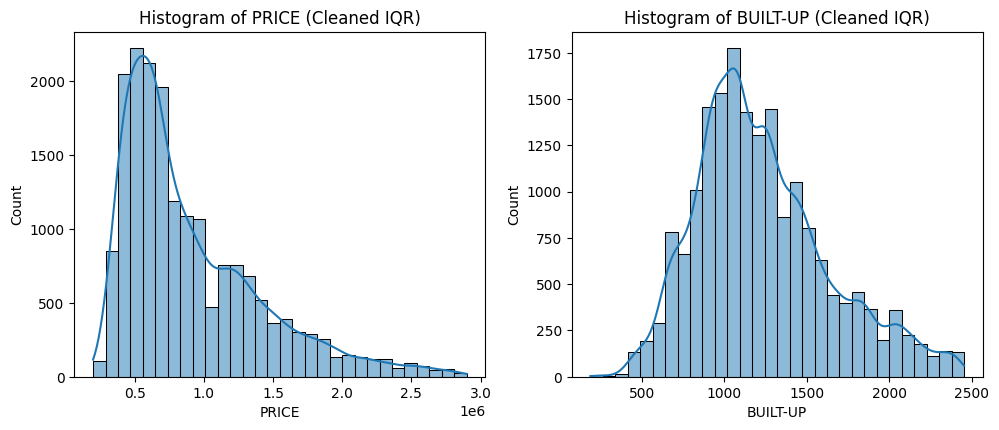

In [24]:
# Ploto the histogram of data_cleaned_iqr

# Ensure your numeric columns are defined
numeric_cols = ['PRICE',
                'BUILT-UP']

# Plot Histograms AFTER cleaning
plt.figure(figsize=(15, 8))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(2, 3, i)
    # Using df_cleaned_iqr here, adding kde=True to show the distribution curve
    sns.histplot(x=df_cleaned_iqr[col], kde=True, bins=30)
    plt.title(f'Histogram of {col} (Cleaned IQR)')
    
plt.tight_layout()
plt.show()

In [25]:
# Define your continuous variables
from scipy.stats import normaltest

numeric_cols = ['PRICE', 'BUILT-UP']

print("--- Normality Evaluation (D'Agostino's K-squared Test) ---")
for col in numeric_cols:
    # Drop NaNs just for these calculations
    data = df_cleaned_iqr[col].dropna()
    
    # Perform D'Agostino's K-squared test (better for large N than Shapiro)
    stat, p_value = normaltest(data)
    
    # Calculate shape metrics
    skew = data.skew()
    kurt = data.kurtosis()
    
    # Interpret the results (using standard alpha level of 0.05)
    if p_value > 0.05:
        distribution = "Normally distributed (Fail to reject H0)"
    else:
        distribution = "NOT normally distributed (Reject H0)"
        
    print(f"{col}:")
    print(f"  Test Statistic: {stat:.4f}")
    print(f"  P-value: {p_value:.4g} -> {distribution}")
    print(f"  Skewness: {skew:.4f} (Ideal range for modeling: -1.0 to 1.0)")
    print(f"  Kurtosis: {kurt:.4f} (Ideal range for modeling: -3.0 to 3.0)\n")

--- Normality Evaluation (D'Agostino's K-squared Test) ---
PRICE:
  Test Statistic: 3840.0274
  P-value: 0 -> NOT normally distributed (Reject H0)
  Skewness: 1.3228 (Ideal range for modeling: -1.0 to 1.0)
  Kurtosis: 1.4650 (Ideal range for modeling: -3.0 to 3.0)

BUILT-UP:
  Test Statistic: 1242.4839
  P-value: 1.578e-270 -> NOT normally distributed (Reject H0)
  Skewness: 0.6958 (Ideal range for modeling: -1.0 to 1.0)
  Kurtosis: 0.1708 (Ideal range for modeling: -3.0 to 3.0)



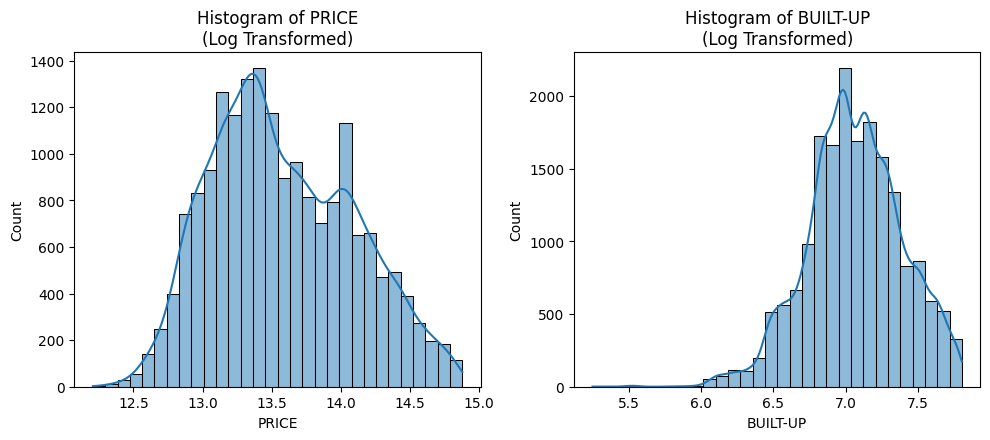

In [26]:
# log transform

# 1. Define your continuous variables
numeric_cols = ['PRICE', 'BUILT-UP']

# 2. Create a new dataframe for the log-transformed data
df_cleaned_transformed = df_cleaned_iqr.copy()

# 3. Apply the log(1+x) transformation to each column
for col in numeric_cols:
    # np.log1p automatically ignores NaNs without crashing
    df_cleaned_transformed[col] = np.log1p(df_cleaned_transformed[col])

# 4. Plot Histograms of the transformed data
plt.figure(figsize=(15, 8))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(2, 3, i)
    sns.histplot(x=df_cleaned_transformed[col], kde=True, bins=30)
    plt.title(f'Histogram of {col}\n(Log Transformed)')
plt.tight_layout()
plt.show()

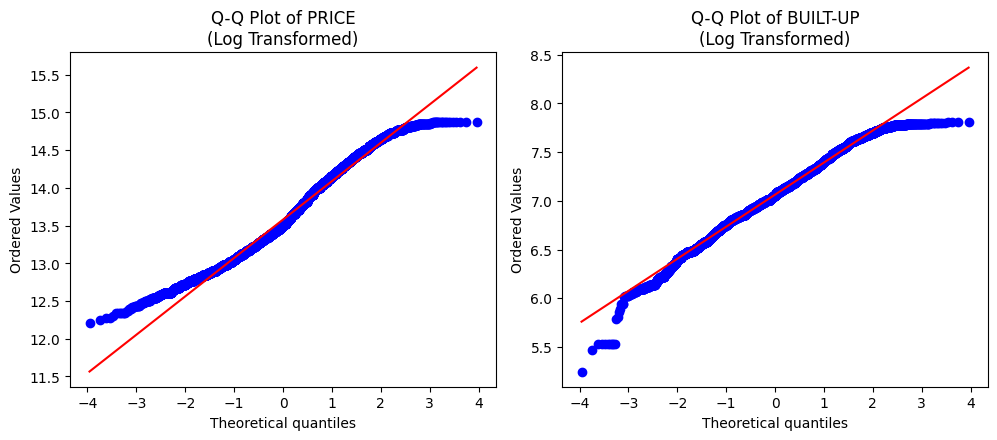

In [27]:
# Define your continuous variables
numeric_cols = ['PRICE', 'BUILT-UP']

# Plot Q-Q plots for the log-transformed data
plt.figure(figsize=(15, 8))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(2, 3, i)
    
    # Drop NaNs just for plotting
    clean_data = df_cleaned_transformed[col].dropna()
    
    # Generate the Q-Q plot
    stats.probplot(clean_data, dist="norm", plot=plt)
    plt.title(f'Q-Q Plot of {col}\n(Log Transformed)')

plt.tight_layout()
plt.show()

In [28]:
# Define your continuous variables
from scipy.stats import normaltest

numeric_cols = ['PRICE', 'BUILT-UP']

print("--- Normality Evaluation (D'Agostino's K-squared Test) ---")
for col in numeric_cols:
    # Drop NaNs just for these calculations
    data = df_cleaned_transformed[col].dropna()
    
    # Perform D'Agostino's K-squared test (better for large N than Shapiro)
    stat, p_value = normaltest(data)
    
    # Calculate shape metrics
    skew = data.skew()
    kurt = data.kurtosis()
    
    # Interpret the results (using standard alpha level of 0.05)
    if p_value > 0.05:
        distribution = "Normally distributed (Fail to reject H0)"
    else:
        distribution = "NOT normally distributed (Reject H0)"
        
    print(f"{col}:")
    print(f"  Test Statistic: {stat:.4f}")
    print(f"  P-value: {p_value:.4g} -> {distribution}")
    print(f"  Skewness: {skew:.4f} (Ideal range for modeling: -1.0 to 1.0)")
    print(f"  Kurtosis: {kurt:.4f} (Ideal range for modeling: -3.0 to 3.0)\n")

--- Normality Evaluation (D'Agostino's K-squared Test) ---
PRICE:
  Test Statistic: 1042.0224
  P-value: 5.342e-227 -> NOT normally distributed (Reject H0)
  Skewness: 0.3125 (Ideal range for modeling: -1.0 to 1.0)
  Kurtosis: -0.6479 (Ideal range for modeling: -3.0 to 3.0)

BUILT-UP:
  Test Statistic: 133.7205
  P-value: 9.182e-30 -> NOT normally distributed (Reject H0)
  Skewness: -0.1973 (Ideal range for modeling: -1.0 to 1.0)
  Kurtosis: 0.1569 (Ideal range for modeling: -3.0 to 3.0)



In [29]:
# 1. Create new columns for the log-transformed data
# We use np.log1p() which applies log(1 + x) - a standard best practice in machine learning
df_cleaned['PRICE_LOG'] = np.log1p(df_cleaned['PRICE'])
df_cleaned['BUILT-UP_LOG'] = np.log1p(df_cleaned['BUILT-UP'])

# 2. Verify the new columns were added
print("First 5 rows of the numerical columns:")
print(df_cleaned[['PRICE', 'PRICE_LOG', 'BUILT-UP', 'BUILT-UP_LOG']].head())

# 3. Export the final dataset to a CSV file on your computer
csv_filename = 'df_cleaned.csv'
df_cleaned.to_csv(csv_filename, index=False)

print(f"\nSuccess! Dataset with log-transformed columns exported to: {csv_filename}")

First 5 rows of the numerical columns:
      PRICE  PRICE_LOG  BUILT-UP  BUILT-UP_LOG
0  200000.0  12.206078     800.0      6.685861
1  210000.0  12.254868     802.0      6.688355
2  215000.0  12.278398     900.0      6.803505
3  215000.0  12.278398     800.0      6.685861
4  220000.0  12.301387     832.0      6.725034

Success! Dataset with log-transformed columns exported to: df_cleaned.csv


In [30]:
df_cleaned_transformed.info()

<class 'pandas.core.frame.DataFrame'>
Index: 18412 entries, 0 to 19833
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   LOCATION            18412 non-null  object 
 1   PRICE               18412 non-null  float64
 2   ROOMS               18412 non-null  float64
 3   BATHROOMS           18412 non-null  float64
 4   CAR_PARKS           18412 non-null  float64
 5   PROPERTY_BASE       18412 non-null  object 
 6   PROPERTY_TYPE       18412 non-null  object 
 7   BUILT-UP            18412 non-null  float64
 8   FURNISHING _STATUS  18412 non-null  object 
dtypes: float64(5), object(4)
memory usage: 1.4+ MB


In [31]:
# Exploratoty data analysis

In [32]:
df_new = pd.read_csv("df_cleaned.csv")
df_new.head()

,LOCATION,PRICE,ROOMS,BATHROOMS,CAR_PARKS,PROPERTY_BASE,PROPERTY_TYPE,BUILT-UP,FURNISHING _STATUS,PRICE_LOG,BUILT-UP_LOG
0,SETAPAK,200000.0,3.0,2.0,1.0,CONDOMINIUM,INTERMEDIATE,800.0,UNFURNISHED,12.206078,6.685861
1,SETAPAK,210000.0,3.0,2.0,1.0,CONDOMINIUM,INTERMEDIATE,802.0,PARTLY FURNISHED,12.254868,6.688355
2,SETAPAK,215000.0,3.0,2.0,1.0,CONDOMINIUM,CORNER,900.0,PARTLY FURNISHED,12.278398,6.803505
3,SETAPAK,215000.0,3.0,2.0,1.0,CONDOMINIUM,INTERMEDIATE,800.0,UNFURNISHED,12.278398,6.685861
4,SETAPAK,220000.0,3.0,2.0,1.0,CONDOMINIUM,CORNER,832.0,PARTLY FURNISHED,12.301387,6.725034


In [33]:
df_new.describe()

,PRICE,ROOMS,BATHROOMS,CAR_PARKS,BUILT-UP,PRICE_LOG,BUILT-UP_LOG
count,2.155800e+04,21558.000000,21558.000000,21558.000000,21558.000000,21558.000000,21558.000000
mean,1.302288e+06,3.230031,2.646628,1.743390,1551.823407,13.783019,7.211947
std,1.345837e+06,1.136797,1.231553,0.822923,988.406586,0.709182,0.488676
min,2.000000e+05,1.000000,1.000000,1.000000,189.000000,12.206078,5.247024
25%,5.650000e+05,3.000000,2.000000,1.000000,985.000000,13.244583,6.893656
50%,8.500000e+05,3.000000,2.000000,2.000000,1250.000000,13.652993,7.131699
75%,1.500000e+06,4.000000,3.000000,2.000000,1712.000000,14.220976,7.446001
max,4.054234e+07,10.000000,20.000000,13.000000,14570.000000,17.517857,9.586789


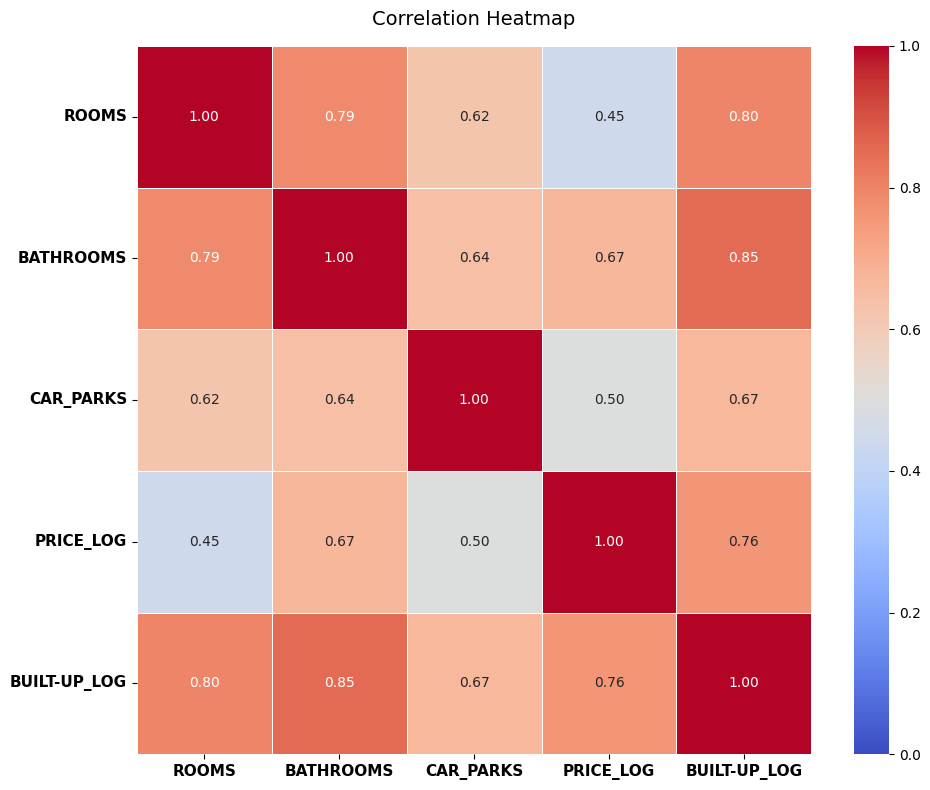

In [34]:
# Plot heatmap 
# 1. Select the specific numerical columns from your screenshot
numerical_cols = ['ROOMS', 'BATHROOMS', 'CAR_PARKS', 'PRICE_LOG', 'BUILT-UP_LOG']
corr_data = df_new[numerical_cols]

# 2. Calculate the correlation matrix (Pearson correlation by default)
correlation_matrix = corr_data.corr()

# 3. Set up the figure size
plt.figure(figsize=(10, 8))
cmap = sns.diverging_palette(240, 10, s=80, l=55, as_cmap=True)

# 4. Plot the heatmap
sns.heatmap(
    correlation_matrix, 
    annot=True,          # Displays the correlation values inside the squares
    cmap='coolwarm',     # Color gradient: Blue (negative) to Red (positive)
    fmt='.2f',           # Rounds the numbers to two decimal places
    linewidths=0.5,      # Adds thin borders between squares for clarity
    vmin=0, vmax=1      # Anchors the color scale strictly from -1 to 1
)

# 5. Add a title and display
plt.title('Correlation Heatmap', fontsize=14, pad=15)
plt.xticks(fontsize=11, fontweight='bold')
plt.yticks(fontsize=11, fontweight='bold', rotation=0)
plt.tight_layout()

plt.savefig('Fig_Correlation.png', dpi=300, bbox_inches='tight')
plt.show()

In [35]:
df_new.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21558 entries, 0 to 21557
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   LOCATION            21558 non-null  object 
 1   PRICE               21558 non-null  float64
 2   ROOMS               21558 non-null  float64
 3   BATHROOMS           21558 non-null  float64
 4   CAR_PARKS           21558 non-null  float64
 5   PROPERTY_BASE       21558 non-null  object 
 6   PROPERTY_TYPE       21558 non-null  object 
 7   BUILT-UP            21558 non-null  float64
 8   FURNISHING _STATUS  21558 non-null  object 
 9   PRICE_LOG           21558 non-null  float64
 10  BUILT-UP_LOG        21558 non-null  float64
dtypes: float64(7), object(4)
memory usage: 1.8+ MB


In [36]:
missing_counts = df_new.isnull().sum()
print(missing_counts)

LOCATION              0
PRICE                 0
ROOMS                 0
BATHROOMS             0
CAR_PARKS             0
PROPERTY_BASE         0
PROPERTY_TYPE         0
BUILT-UP              0
FURNISHING _STATUS    0
PRICE_LOG             0
BUILT-UP_LOG          0
dtype: int64
